Carga de los archivos procesados:

In [46]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

PROCESSED_DIR = ROOT_DIR / "data" / "processed"

peliculas = pd.read_csv(
    PROCESSED_DIR / "peliculas_procesadas.csv"
)

series = pd.read_csv(
    PROCESSED_DIR / "series_procesadas.csv"
)

print("Películas:", peliculas.shape)
print("Series:", series.shape)



Películas: (16000, 18)
Series: (15991, 16)


Analizar la distribución del catálogo por año

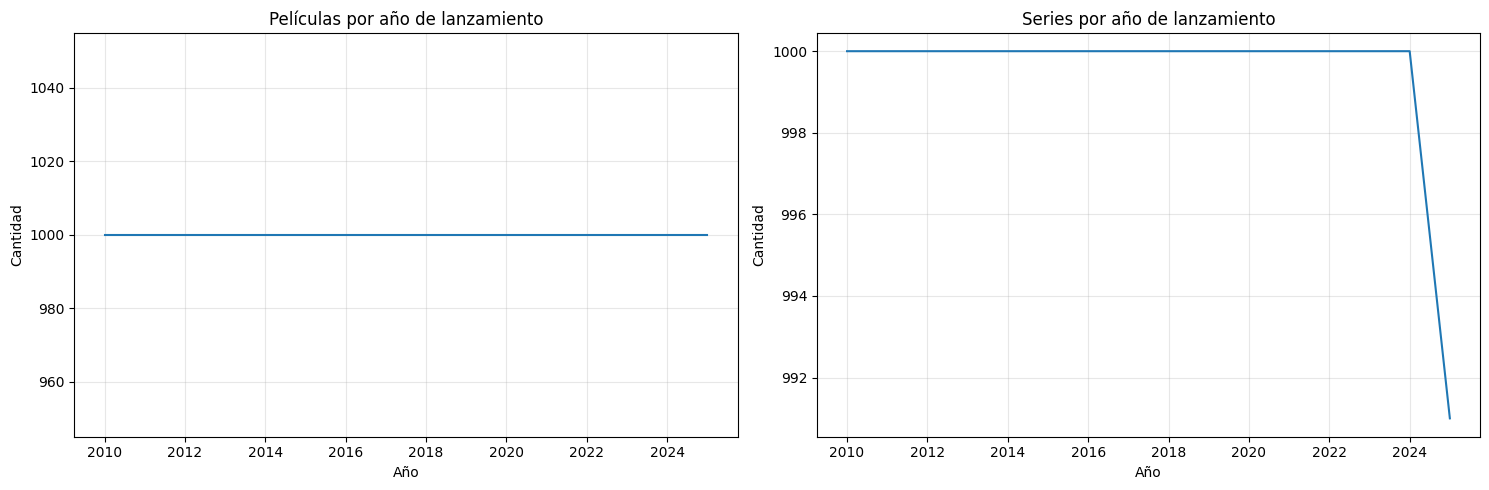

In [47]:

# Distribución de películas y series por año de lanzamiento

peliculas["release_year"] = pd.to_numeric(
    peliculas["release_year"], errors="coerce"
)

series["release_year"] = pd.to_numeric(
    series["release_year"], errors="coerce"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

peliculas["release_year"].value_counts().sort_index().plot(
    ax=axes[0], kind="line"
)
axes[0].set_title("Películas por año de lanzamiento")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Cantidad")
axes[0].grid(True, alpha=0.3)

series["release_year"].value_counts().sort_index().plot(
    ax=axes[1], kind="line"
)
axes[1].set_title("Series por año de lanzamiento")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Cantidad")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Revisar los datos por año

In [48]:

print("=== PELÍCULAS POR AÑO ===")
print(
    peliculas["release_year"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\n=== SERIES POR AÑO ===")
print(
    series["release_year"]
    .value_counts()
    .sort_index()
    .to_string()
)


=== PELÍCULAS POR AÑO ===
release_year
2010    1000
2011    1000
2012    1000
2013    1000
2014    1000
2015    1000
2016    1000
2017    1000
2018    1000
2019    1000
2020    1000
2021    1000
2022    1000
2023    1000
2024    1000
2025    1000

=== SERIES POR AÑO ===
release_year
2010    1000
2011    1000
2012    1000
2013    1000
2014    1000
2015    1000
2016    1000
2017    1000
2018    1000
2019    1000
2020    1000
2021    1000
2022    1000
2023    1000
2024    1000
2025     991


Comprobar si hay una distribución artificialmente uniforme

In [49]:

print("Películas: estadísticas por año")
print(peliculas["release_year"].describe())

print("\nSeries: estadísticas por año")
print(series["release_year"].describe())

print("\nPelículas: años con menor frecuencia")
print(peliculas["release_year"].value_counts().nsmallest(10))

print("\nSeries: años con menor frecuencia")
print(series["release_year"].value_counts().nsmallest(10))


Películas: estadísticas por año
count    16000.000000
mean      2017.500000
std          4.609916
min       2010.000000
25%       2013.750000
50%       2017.500000
75%       2021.250000
max       2025.000000
Name: release_year, dtype: float64

Series: estadísticas por año
count    15991.000000
mean      2017.495779
std          4.607777
min       2010.000000
25%       2013.000000
50%       2017.000000
75%       2021.000000
max       2025.000000
Name: release_year, dtype: float64

Películas: años con menor frecuencia
release_year
2010    1000
2011    1000
2012    1000
2013    1000
2014    1000
2015    1000
2016    1000
2017    1000
2018    1000
2019    1000
Name: count, dtype: int64

Series: años con menor frecuencia
release_year
2025     991
2010    1000
2011    1000
2012    1000
2013    1000
2014    1000
2015    1000
2016    1000
2017    1000
2018    1000
Name: count, dtype: int64


Análisis de los géneros más frecuentes

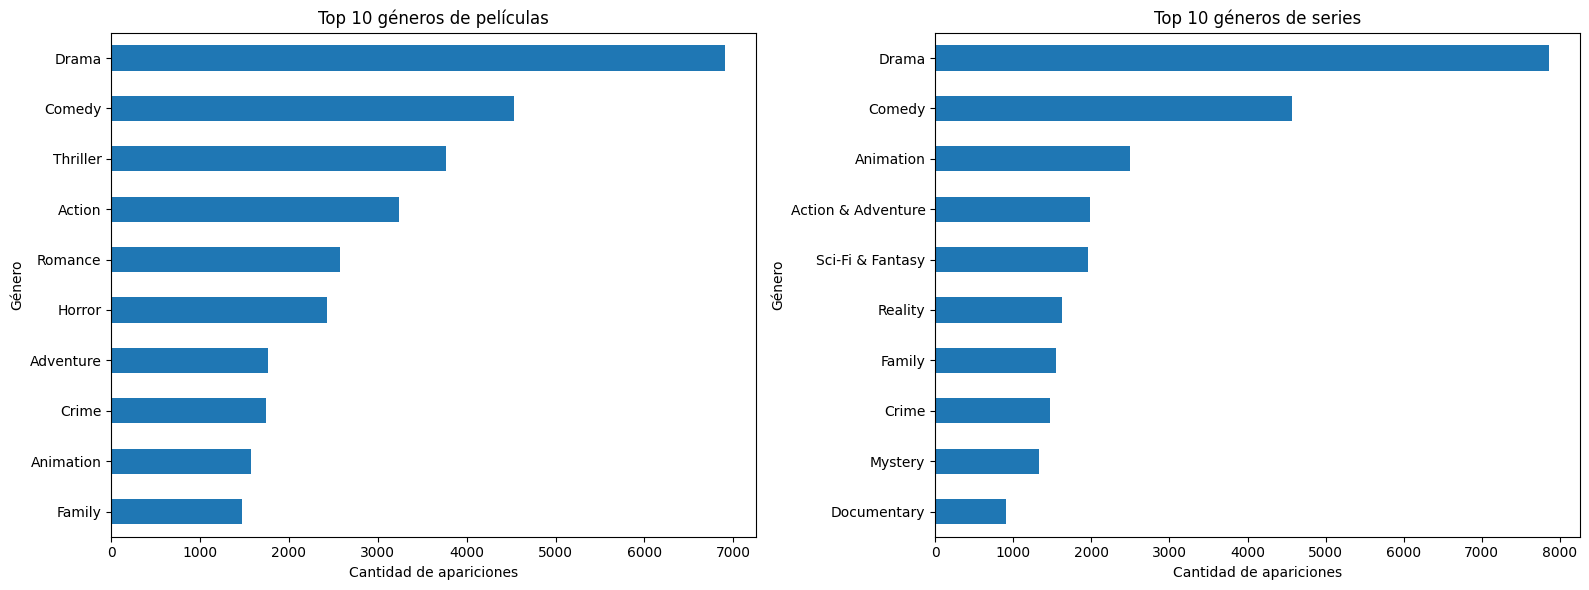

In [50]:
def contar_generos(df):
    return (
        df["genres"]
        .dropna()
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
        .replace("", pd.NA)
        .dropna()
        .value_counts()
    )

generos_peliculas = contar_generos(peliculas)
generos_series = contar_generos(series)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

generos_peliculas.head(10).sort_values().plot(
    kind="barh", ax=axes[0]
)
axes[0].set_title("Top 10 géneros de películas")
axes[0].set_xlabel("Cantidad de apariciones")
axes[0].set_ylabel("Género")

generos_series.head(10).sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Top 10 géneros de series")
axes[1].set_xlabel("Cantidad de apariciones")
axes[1].set_ylabel("Género")

plt.tight_layout()
plt.show()


Se cuentan apariciones de géneros, no títulos únicos.

Analizar la popularidad y las valoraciones

In [51]:

# Estadísticas descriptivas de popularidad y valoraciones

columnas = ["popularity", "vote_count", "vote_average"]

print("=== PELÍCULAS ===")
display(peliculas[columnas].describe().round(2))

print("=== SERIES ===")
display(series[columnas].describe().round(2))


=== PELÍCULAS ===


,popularity,vote_count,vote_average
count,16000.00,16000.00,16000.00
mean,20.38,718.66,5.96
std,68.61,2080.20,1.75
min,3.86,0.00,0.00
25%,7.84,53.00,5.60
50%,10.91,138.00,6.30
75%,17.34,422.00,6.92
max,3876.01,37119.00,10.00


=== SERIES ===


,popularity,vote_count,vote_average
count,15991.00,15991.00,15991.00
mean,64.88,107.07,5.42
std,139.42,607.63,3.27
min,2.32,0.00,0.00
25%,24.90,1.00,2.80
50%,36.20,4.00,6.80
75%,62.22,30.00,7.80
max,6421.92,24664.00,10.00


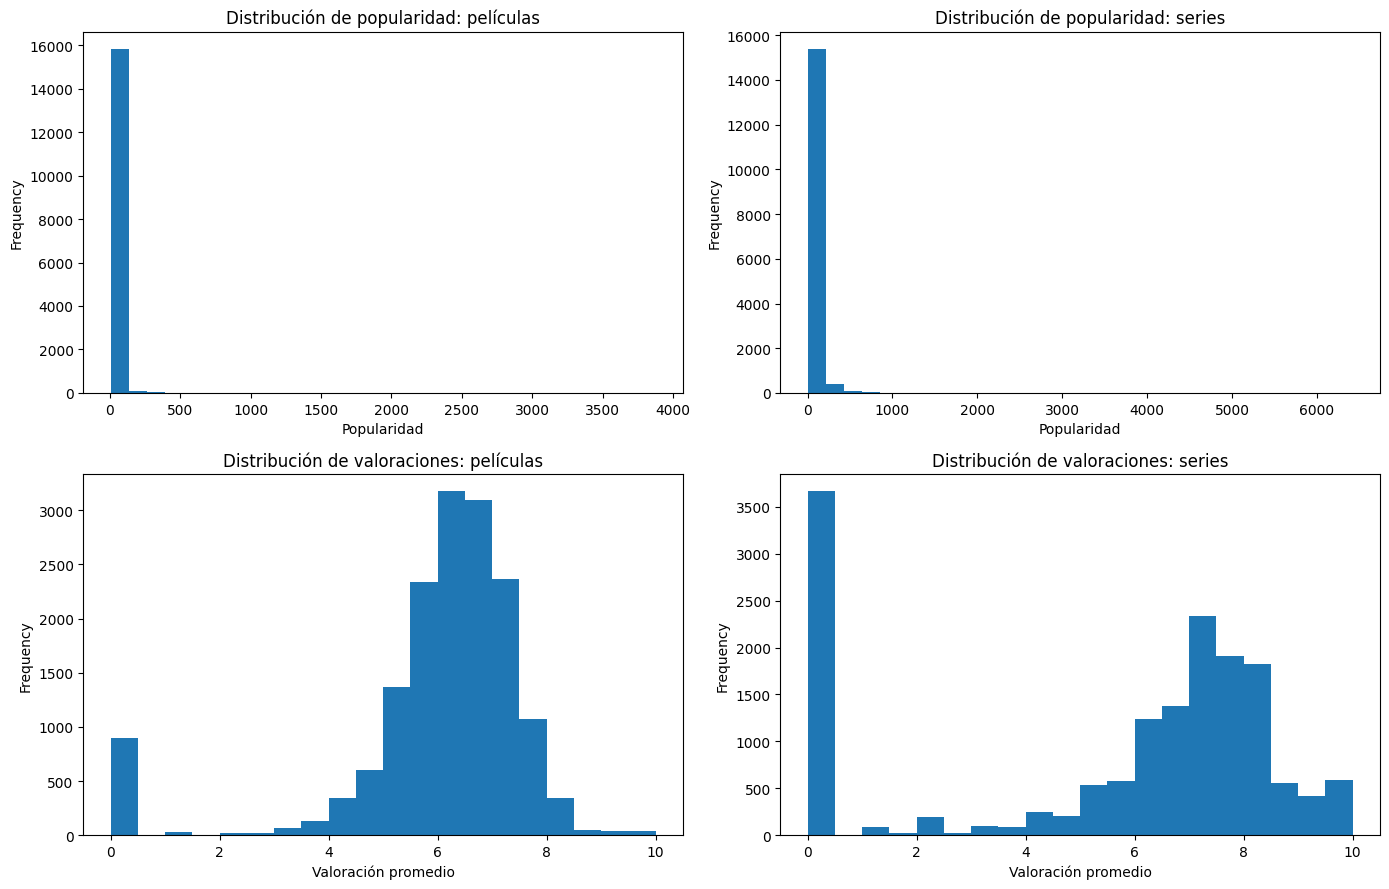

In [52]:

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

peliculas["popularity"].dropna().plot(
    kind="hist", bins=30, ax=axes[0, 0]
)
axes[0, 0].set_title("Distribución de popularidad: películas")
axes[0, 0].set_xlabel("Popularidad")

series["popularity"].dropna().plot(
    kind="hist", bins=30, ax=axes[0, 1]
)
axes[0, 1].set_title("Distribución de popularidad: series")
axes[0, 1].set_xlabel("Popularidad")

peliculas["vote_average"].dropna().plot(
    kind="hist", bins=20, ax=axes[1, 0]
)
axes[1, 0].set_title("Distribución de valoraciones: películas")
axes[1, 0].set_xlabel("Valoración promedio")

series["vote_average"].dropna().plot(
    kind="hist", bins=20, ax=axes[1, 1]
)
axes[1, 1].set_title("Distribución de valoraciones: series")
axes[1, 1].set_xlabel("Valoración promedio")

plt.tight_layout()
plt.show()


**Interpretación del año de lanzamiento**

La distribución muestra 1.000 películas por año entre 2010 y 2025. En las series se observan 1.000 registros anuales entre 2010 y 2024, y 991 para 2025. Esta uniformidad es un patrón relevante de los datos disponibles y podría responder a criterios de selección o preparación del conjunto. No obstante, sin información adicional sobre su construcción, no es posible determinar su causa.

Por lo tanto, esta distribución debe considerarse una limitación al momento de generalizar los resultados al catálogo completo de una plataforma de streaming.

Investigar las valoraciones iguales a cero

In [53]:

def auditar_valoraciones(df, nombre):
    print(f"=== {nombre} ===")

    total = len(df)
    sin_valoracion = df["vote_average"].eq(0).sum()
    sin_votos = df["vote_count"].eq(0).sum()
    ambos_cero = (
        df["vote_average"].eq(0)
        & df["vote_count"].eq(0)
    ).sum()

    print(f"Total de registros: {total}")
    print(
        f"Valoración igual a cero: {sin_valoracion} "
        f"({sin_valoracion / total:.2%})"
    )
    print(
        f"Cantidad de votos igual a cero: {sin_votos} "
        f"({sin_votos / total:.2%})"
    )
    print(
        f"Ambas variables iguales a cero: {ambos_cero} "
        f"({ambos_cero / total:.2%})"
    )

auditar_valoraciones(peliculas, "PELÍCULAS")
print()
auditar_valoraciones(series, "SERIES")


=== PELÍCULAS ===
Total de registros: 16000
Valoración igual a cero: 899 (5.62%)
Cantidad de votos igual a cero: 894 (5.59%)
Ambas variables iguales a cero: 894 (5.59%)

=== SERIES ===
Total de registros: 15991
Valoración igual a cero: 3665 (22.92%)
Cantidad de votos igual a cero: 3666 (22.93%)
Ambas variables iguales a cero: 3653 (22.84%)


Revisar los registros con ceros

In [54]:

columnas_revision = [
    "title",
    "popularity",
    "vote_count",
    "vote_average"
]

print("=== PELÍCULAS SIN VOTOS ===")
display(
    peliculas.loc[
        peliculas["vote_count"].eq(0),
        columnas_revision
    ].head(10)
)

print("=== SERIES SIN VOTOS ===")
display(
    series.loc[
        series["vote_count"].eq(0),
        columnas_revision
    ].head(10)
)


=== PELÍCULAS SIN VOTOS ===


,title,popularity,vote_count,vote_average
853,Eros Photographer,4.588,0,0.0
1989,Sonríe,4.399,0,0.0
2480,YtF,9.069,0,0.0
2983,SP Woman - Beautiful Sacrifice,4.903,0,0.0
3256,Torchlighters: The Augustine Story,14.589,0,0.0
3767,Invisible Hentai Man,6.475,0,0.0
4581,48 Days,9.261,0,0.0
4609,An Affair: A Dangerous Sexual Play,8.870,0,0.0
5120,Isuca: Gokuraku,24.842,0,0.0
5512,Hipster,9.412,0,0.0


=== SERIES SIN VOTOS ===


,title,popularity,vote_count,vote_average
5,Euphrosyne,629.982,0,0.0
8,Zone,489.739,0,0.0
10,Atomes crochus,463.962,0,0.0
20,A Masterpiece in 100 Minutes,338.901,0,0.0
22,All My Love For You,314.291,0,0.0
32,Peter Hahne,252.021,0,0.0
40,Rubi,222.934,0,0.0
41,Word to a Woman,240.249,0,0.0
49,Only You,191.646,0,0.0
50,Scarlet Letter,182.038,0,0.0


Analizar la relación entre las variables

In [55]:

# Correlaciones entre popularidad, votos y valoración

columnas = ["popularity", "vote_count", "vote_average"]

print("=== CORRELACIONES: PELÍCULAS ===")
display(peliculas[columnas].corr().round(3))

print("=== CORRELACIONES: SERIES ===")
display(series[columnas].corr().round(3))


=== CORRELACIONES: PELÍCULAS ===


,popularity,vote_count,vote_average
popularity,1.000,0.158,0.071
vote_count,0.158,1.000,0.174
vote_average,0.071,0.174,1.000


=== CORRELACIONES: SERIES ===


,popularity,vote_count,vote_average
popularity,1.000,0.145,0.052
vote_count,0.145,1.000,0.132
vote_average,0.052,0.132,1.000


Visualizar la relación entre popularidad y votos

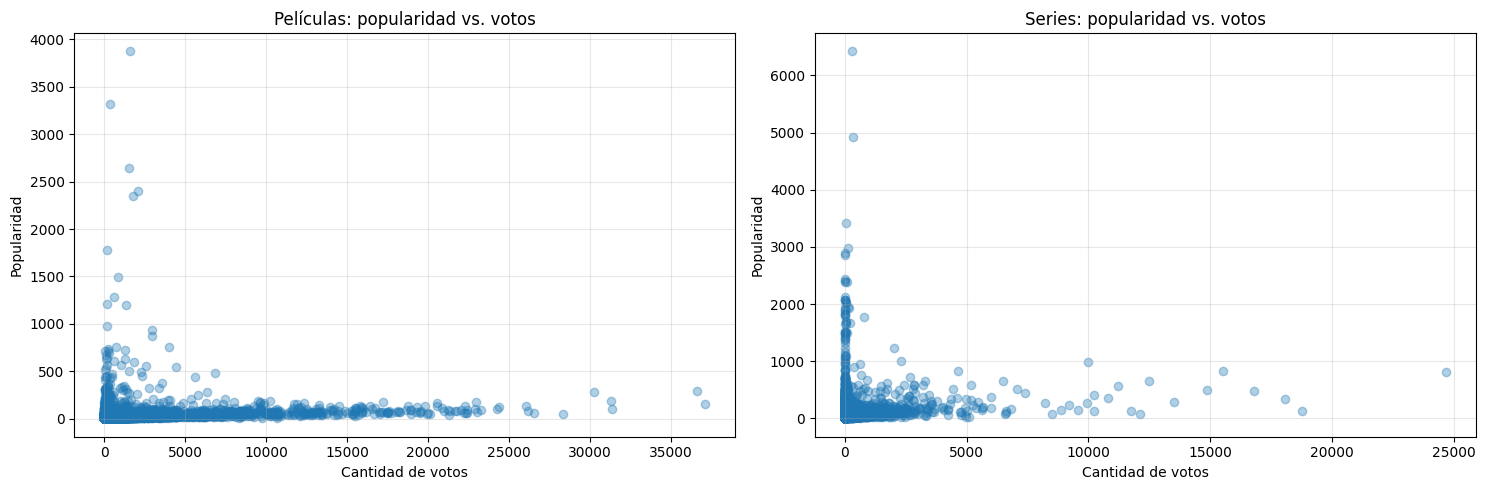

In [56]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(
    peliculas["vote_count"],
    peliculas["popularity"],
    alpha=0.35
)
axes[0].set_title("Películas: popularidad vs. votos")
axes[0].set_xlabel("Cantidad de votos")
axes[0].set_ylabel("Popularidad")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(
    series["vote_count"],
    series["popularity"],
    alpha=0.35
)
axes[1].set_title("Series: popularidad vs. votos")
axes[1].set_xlabel("Cantidad de votos")
axes[1].set_ylabel("Popularidad")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


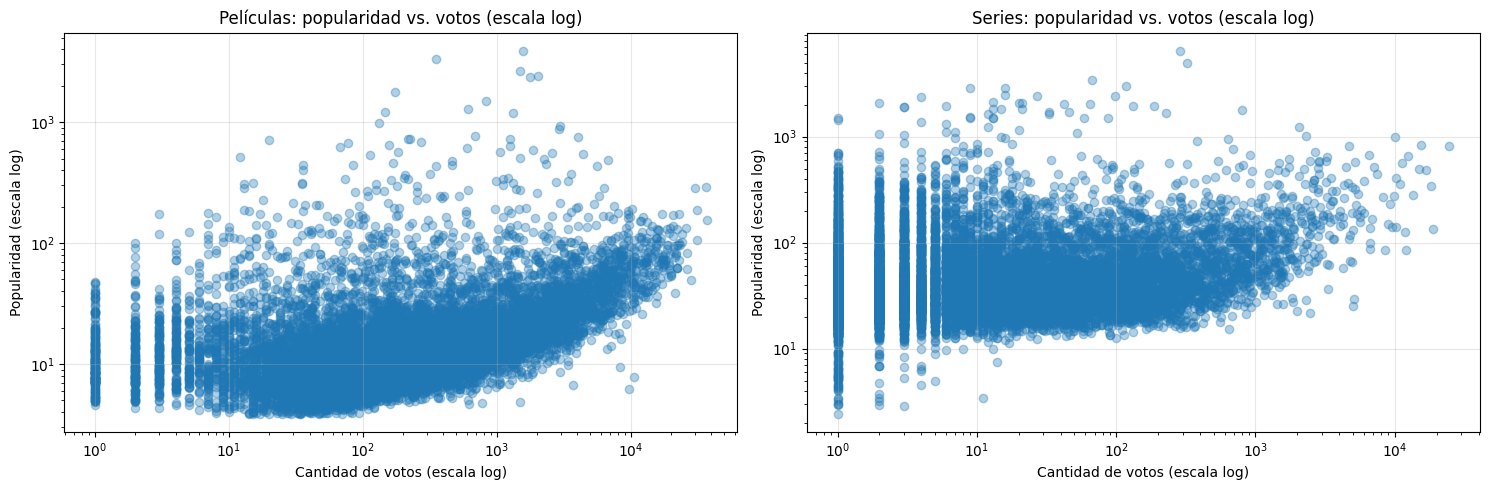

In [57]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, df, titulo in [
    (axes[0], peliculas, "Películas"),
    (axes[1], series, "Series")
]:
    datos = df[
        (df["vote_count"] > 0) &
        (df["popularity"] > 0)
    ]

    ax.scatter(
        datos["vote_count"],
        datos["popularity"],
        alpha=0.35
    )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{titulo}: popularidad vs. votos (escala log)")
    ax.set_xlabel("Cantidad de votos (escala log)")
    ax.set_ylabel("Popularidad (escala log)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretación de las correlaciones**

Las correlaciones de Pearson observadas son positivas, pero débiles en ambos conjuntos. La relación entre popularidad y cantidad de votos es de 0,158 en películas y 0,145 en series. Por su parte, la relación entre popularidad y puntuación es todavía menor.

Estos resultados indican que no existe una asociación lineal fuerte entre las variables analizadas. Por ello, la popularidad, las puntuaciones y la cantidad de votos deben evaluarse como dimensiones diferentes. Además, correlación no implica causalidad y los resultados dependen de la calidad y representatividad de los datos disponibles.

Revisar la clasificación del contenido

In [58]:

# Distribución de las clasificaciones del contenido

print("=== CLASIFICACIONES DE PELÍCULAS ===")
print(peliculas["rating"].value_counts(dropna=False))

print("\n=== CLASIFICACIONES DE SERIES ===")
print(series["rating"].value_counts(dropna=False))


=== CLASIFICACIONES DE PELÍCULAS ===
rating
0.000    899
6.000    536
6.500    497
6.400    494
6.300    491
        ... 
7.478      1
6.615      1
7.714      1
7.455      1
9.400      1
Name: count, Length: 2145, dtype: int64

=== CLASIFICACIONES DE SERIES ===
rating
0.000     3665
7.000      772
8.000      753
6.000      583
10.000     471
          ... 
7.494        1
7.118        1
8.016        1
9.667        1
6.818        1
Name: count, Length: 1184, dtype: int64


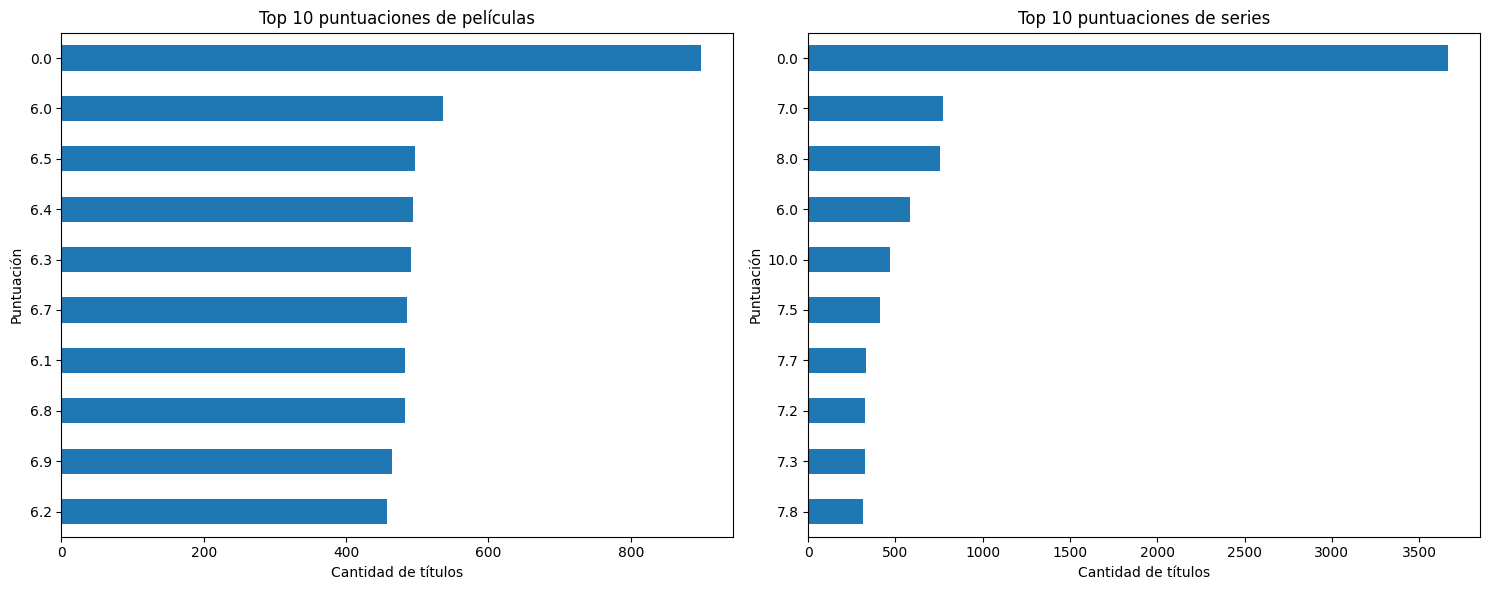

In [66]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

peliculas["rating"].value_counts().head(10).sort_values().plot(
    kind="barh", ax=axes[0]
)
axes[0].set_title("Top 10 puntuaciones de películas")
axes[0].set_xlabel("Cantidad de títulos")
axes[0].set_ylabel("Puntuación")

series["rating"].value_counts().head(10).sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Top 10 puntuaciones de series")
axes[1].set_xlabel("Cantidad de títulos")
axes[1].set_ylabel("Puntuación")

plt.tight_layout()
plt.show()


Revisar la duración

In [60]:

print("=== AUDITORÍA DE DURACIÓN ===")

print(
    "Películas: valores nulos =",
    peliculas["duration"].isna().sum(),
    "de",
    len(peliculas)
)

print(
    "Series: valores nulos =",
    series["duration"].isna().sum(),
    "de",
    len(series)
)

print("\nEjemplos de duración de series:")
display(series[["title", "duration"]].head(10))


=== AUDITORÍA DE DURACIÓN ===
Películas: valores nulos = 16000 de 16000
Series: valores nulos = 0 de 15991

Ejemplos de duración de series:


,title,duration
0,Running Man,1 Seasons
1,Conan,1 Seasons
2,MasterChef Greece,1 Seasons
3,Prostřeno!,1 Seasons
4,The Talk,1 Seasons
5,Euphrosyne,1 Seasons
6,Hawaii Five-0,1 Seasons
7,The Walking Dead,1 Seasons
8,Zone,1 Seasons
9,Regular Show,1 Seasons


Preparar el análisis de duración de series

In [61]:

# Extraer la cantidad de temporadas desde la duración original

series["temporadas"] = pd.to_numeric(
    series["duration"]
    .astype("string")
    .str.extract(r"(\d+)")[0],
    errors="coerce"
)

print("Estadísticas de temporadas:")
display(series["temporadas"].describe())

print("\nCantidad de series por número de temporadas:")
print(series["temporadas"].value_counts().sort_index())


Estadísticas de temporadas:


count    15991.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: temporadas, dtype: Float64


Cantidad de series por número de temporadas:
temporadas
1    15991
Name: count, dtype: Int64


### Analizar la distribución de las puntuaciones del contenido

En esta sección se analiza la distribución de la variable `rating`, que contiene puntuaciones numéricas entre 0 y 10. Se comparan películas y series para observar sus distribuciones, tendencias centrales y diferencias, considerando que los valores iguales a cero requieren una interpretación cuidadosa.

=== PUNTUACIONES DE PELÍCULAS ===


,rating
count,16000.00
mean,5.96
std,1.75
min,0.00
25%,5.60
50%,6.30
75%,6.92
max,10.00



=== PUNTUACIONES DE SERIES ===


,rating
count,15991.00
mean,5.42
std,3.27
min,0.00
25%,2.80
50%,6.80
75%,7.80
max,10.00


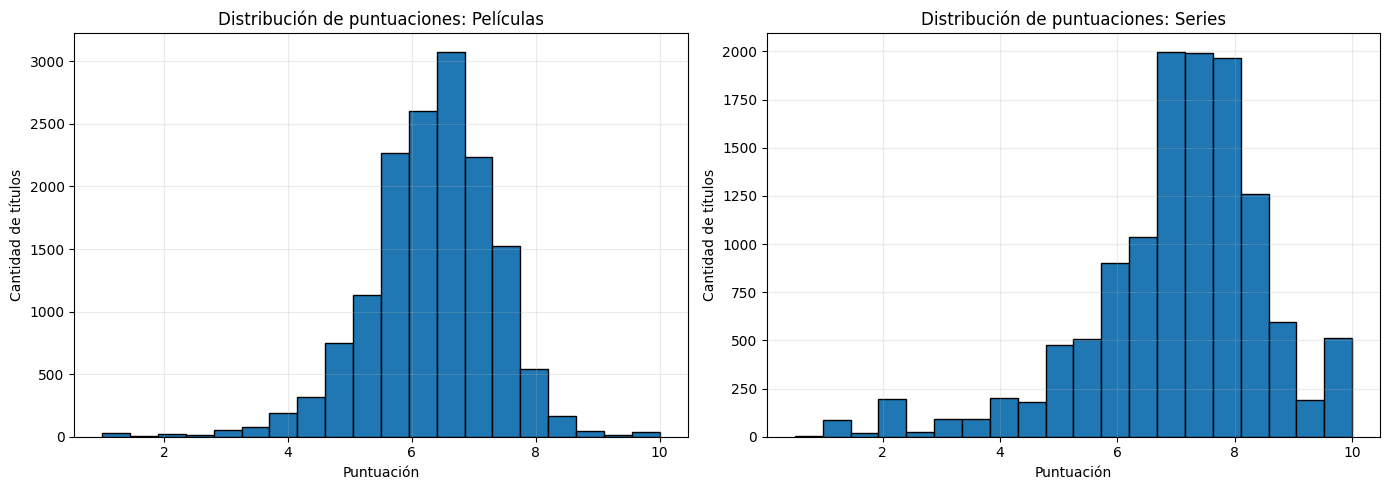

In [62]:

# Estadísticas descriptivas de las puntuaciones

columnas_rating = ["rating"]

print("=== PUNTUACIONES DE PELÍCULAS ===")
display(peliculas[columnas_rating].describe().round(2))

print("\n=== PUNTUACIONES DE SERIES ===")
display(series[columnas_rating].describe().round(2))

# Distribución de las puntuaciones, excluyendo los ceros solo
# de la visualización para observar mejor las puntuaciones positivas.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, df, nombre in [
    (axes[0], peliculas, "Películas"),
    (axes[1], series, "Series")
]:
    puntuaciones = df.loc[df["rating"] > 0, "rating"]

    ax.hist(puntuaciones, bins=20, edgecolor="black")
    ax.set_title(f"Distribución de puntuaciones: {nombre}")
    ax.set_xlabel("Puntuación")
    ax.set_ylabel("Cantidad de títulos")
    ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


In [63]:

print("=== VALORES ORIGINALES DE DURACIÓN ===")

print("\nPelículas:")
print(peliculas["duration"].value_counts(dropna=False).head(10))

print("\nSeries:")
print(series["duration"].value_counts(dropna=False).head(20))

print("\nCantidad de valores distintos:")
print("Películas:", peliculas["duration"].nunique(dropna=False))
print("Series:", series["duration"].nunique(dropna=False))

print("\nEjemplos de series con su duración:")
display(
    series[["title", "release_year", "duration"]].sample(
        min(15, len(series)),
        random_state=42
    )
)


=== VALORES ORIGINALES DE DURACIÓN ===

Películas:
duration
NaN    16000
Name: count, dtype: int64

Series:
duration
1 Seasons    15991
Name: count, dtype: int64

Cantidad de valores distintos:
Películas: 1
Series: 1

Ejemplos de series con su duración:


,title,release_year,duration
15980,حكاية لونا,2025,1 Seasons
7814,Land of the Lustrous,2017,1 Seasons
150,Zig and Sharko,2010,1 Seasons
1684,Al Kherbah,2011,1 Seasons
7497,Niko and the Sword of Light,2017,1 Seasons
5206,Six Flying Dragons,2015,1 Seasons
1034,Rosa Fogo,2011,1 Seasons
123,Kristine,2010,1 Seasons
88,Scooby-Doo! Mystery Incorporated,2010,1 Seasons
5381,Return of Happiness,2015,1 Seasons


**Limitación del análisis de duración**

    La variable `duration` no contiene información útil para comparar la duración de los contenidos: en las películas presenta valores nulos y en las series registra una temporada para todos los títulos. Por lo tanto, no es posible obtener una distribución representativa de la duración ni comparar la cantidad de temporadas a partir de estos archivos.

## Conclusiones del análisis exploratorio

El análisis exploratorio permitió caracterizar los conjuntos de películas y series mediante la distribución por año de lanzamiento, los géneros más frecuentes, las puntuaciones, la popularidad, la cantidad de votos y la calidad de los datos.

Los resultados muestran una distribución uniforme de los registros por año entre 2010 y 2025, por lo que esta variable no presenta la concentración temporal que podría esperarse en un catálogo real. Drama y Comedy aparecen entre los géneros más frecuentes en ambos conjuntos.

Las series presentan una popularidad promedio superior a la de las películas, mientras que las películas tienen una puntuación promedio ligeramente mayor. Sin embargo, las correlaciones entre popularidad, votos y puntuaciones son débiles, lo que indica que estas variables deben analizarse de manera independiente.

La auditoría de calidad identificó valores cero en las puntuaciones, registros duplicados por identificador en las series originales y limitaciones importantes en la variable de duración. Se comprobó que la duración de las películas está completamente vacía y que todas las series originales tienen registrada una temporada. Estas limitaciones provienen de los archivos originales y deben considerarse al interpretar los resultados.

En consecuencia, el EDA permite describir las características del conjunto disponible, pero sus hallazgos deben interpretarse con cautela debido a las limitaciones de calidad y representatividad detectadas.